Loading POS_CASH_balance sample...
Loaded 250,000 monthly snapshots for 145,461 POS loan clients.
Matched with 19,993 clients in application_train.csv.


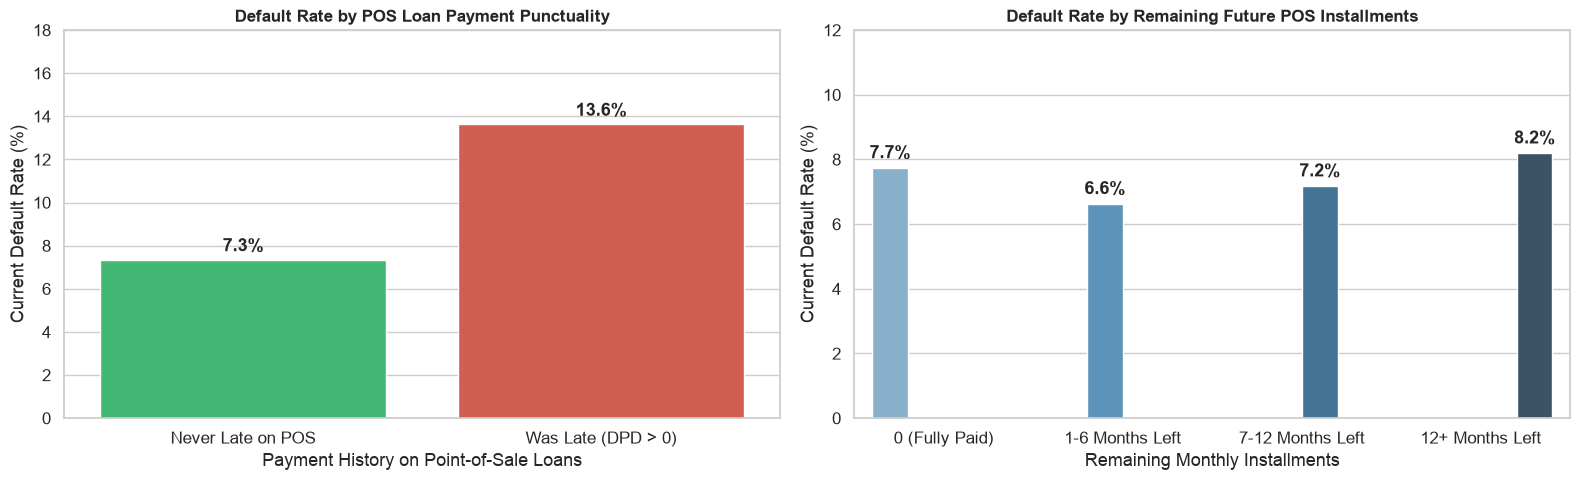

In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", font_scale=1.1)

# Smart Path Finder
data_dir = Path("data") if Path("data").exists() else (Path("../data") if Path("../data").exists() else Path("../../data"))

print("Loading POS_CASH_balance sample...")
use_cols = ['SK_ID_CURR', 'MONTHS_BALANCE', 'CNT_INSTALMENT_FUTURE', 'NAME_CONTRACT_STATUS', 'SK_DPD']
pos = pd.read_csv(data_dir / "POS_CASH_balance.csv", usecols=use_cols, nrows=250000)
app = pd.read_csv(data_dir / "application_train.csv", usecols=["SK_ID_CURR", "TARGET"], nrows=50000)

print(f"Loaded {len(pos):,} monthly snapshots for {pos['SK_ID_CURR'].nunique():,} POS loan clients.")


# 1. Aggregate per Applicant (1 row per person)
pos_agg = pos.groupby("SK_ID_CURR").agg(
    POS_COUNT=("MONTHS_BALANCE", "count"),
    POS_MAX_DPD=("SK_DPD", "max"),
    POS_REMAINING_INSTALMENTS=("CNT_INSTALMENT_FUTURE", "max")
).reset_index()

# Merge with Target
merged_pos = app.merge(pos_agg, on="SK_ID_CURR", how="inner")
print(f"Matched with {len(merged_pos):,} clients in application_train.csv.")


# 2. Side-by-Side Visualizations
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# ─── Panel 1: Late on POS Loans vs Default Rate ───
merged_pos["WAS_LATE_POS"] = (merged_pos["POS_MAX_DPD"] > 0).astype(int)
default_by_pos_late = merged_pos.groupby("WAS_LATE_POS")["TARGET"].mean() * 100
late_labels = ["Never Late on POS", "Was Late (DPD > 0)"]

sns.barplot(
    x=late_labels,
    y=default_by_pos_late.values,
    hue=late_labels,
    palette=["#2ecc71", "#e74c3c"],
    legend=False,
    ax=ax1
)
ax1.set_title("Default Rate by POS Loan Payment Punctuality", fontsize=12, fontweight="bold")
ax1.set_xlabel("Payment History on Point-of-Sale Loans")
ax1.set_ylabel("Current Default Rate (%)")
ax1.set_ylim(0, 18)
for p in ax1.patches:
    ax1.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2, p.get_height() + 0.4), ha="center", fontweight="bold")


# ─── Panel 2: Remaining Future Installments vs Default Rate ───
merged_pos["FUTURE_BIN"] = pd.cut(
    merged_pos["POS_REMAINING_INSTALMENTS"],
    bins=[-1, 0, 6, 12, 60],
    labels=["0 (Fully Paid)", "1-6 Months Left", "7-12 Months Left", "12+ Months Left"]
)
default_by_future = merged_pos.groupby("FUTURE_BIN", observed=False)["TARGET"].mean() * 100

sns.barplot(
    x=default_by_future.index,
    y=default_by_future.values,
    hue=default_by_future.index,
    palette="Blues_d",
    legend=False,
    ax=ax2
)
ax2.set_title("Default Rate by Remaining Future POS Installments", fontsize=12, fontweight="bold")
ax2.set_xlabel("Remaining Monthly Installments")
ax2.set_ylabel("Current Default Rate (%)")
ax2.set_ylim(0, 12)
for p in ax2.patches:
    ax2.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2, p.get_height() + 0.3), ha="center", fontweight="bold")

plt.tight_layout()
plt.show()